# Surface fluxes: CAMulator vs CESM

A climatological mean of one CAMulator variable against one CESM variable, over
whatever window you ask for. Set the knobs in the next cell; nothing below them is
hardcoded.

Run this on an **NPL kernel** — the default JupyterHub kernel has no zarr engine.

**Two steps.** The CAMulator side is one file per day, so reading it is the slow
part. `build_flux_cache` walks each day once, pulls all six fluxes out of it at a
time, averages both models to monthly means and writes them to scratch — about a
minute per year. After that, changing `CAM_VAR`, the latitude band, or the window
costs nothing.

The six cached fluxes are the ones `output/<CASE>/fluxes/` has directories for:

```
FLDS_J   downwelling longwave      FSDS_J   downwelling shortwave
FLUS     upwelling longwave        FSUS     upwelling shortwave
SHFLX    sensible heat             LHFLX    latent heat
```

**All six come back in W/m².** Both models store them as `J m-2` accumulated over
one 6-hour step, so the raw values run to millions; `ice_ens.fluxes` divides by
21600 on read. The cache on scratch still holds the per-step energy, which is why
opening one of those files directly shows numbers of order 1e6. Sign convention is
positive into the surface, so `SHFLX` and `LHFLX` plot negative.

Anything else CAMulator writes (`TREFHT TS PS PRECT QFLX U10 TAUX TAUY FSUTOA
FLUT CLDHGH CLDLOW CLDMED`) is not cached — pass `cache=False` to `flux_series`
to read it straight off the raw output instead.

**Nothing is regridded here.** Both models are already on the same 192×288
lat/lon grid, unlike the ice comparison, which regrids onto gx1v7.

In [1]:
from ice_ens import (build_flux_cache, flux_series, plot_series,
                     flux_map, plot_maps, flux_map_months, plot_map_grid,
                     flux_day, flux_daily,
                     flux_balance, flux_budget, plot_balance)

## Knobs

In [2]:
CASE        = "ck70"        # checkpoint; the camulator_out path is built from this
YEARS       = (1980)  # 1980 | (1980, 1984) | (1980, 1989) — inclusive range
CLIMATOLOGY = False       # True: 12-month mean over YEARS.  False: month-by-month
MONTHS      = 1         # series only: None = every month | 1 = Januarys | (6, 7, 8) = JJA
LAT_RANGE   = (60, 90)      # (south, north) in degrees; None for the global mean
CAM_VAR     = "FLDS_J"        # <- the CAMulator variable
CESM_VAR    = "FLDS_J"        # <- the CESM variable (same name = one shared y axis)

# maps only
REGION      = "north"       # "north" -> Arctic | "south" -> Antarctic | "global"
SEASON      = (1)     # None = annual | 7 = Julys | (6, 7, 8) = JJA | (12, 1, 2) = DJF
DAY         = "1980-01-01" # initial conditions; any YYYY-MM-DD in the run
STEP_MONTH  = "1980-01"    # day-by-day series; YYYY-MM for a month, YYYY-MM-DD for a day


## Build the cache — once per checkpoint

Slow the first time (~1 min per year of CAMulator output), instant afterwards. The
cache is **one file per year**, so widening `YEARS` later only builds the years it
adds: going from 1980–1984 to 1980–1989 costs five years, not ten.

It lands in `/glade/derecho/scratch/tvoeller/honors_thesis/flux_cache/<CASE>/`.
Scratch is purged every 90 days — this is derived data, so if it disappears just
run this cell again.

In [6]:
build_flux_cache(CASE, YEARS)

{'camulator': ['/glade/derecho/scratch/tvoeller/honors_thesis/flux_cache/ck70/camulator_fluxes_monthly_1980.nc'],
 'cesm': ['/glade/derecho/scratch/tvoeller/honors_thesis/flux_cache/ck70/cesm_fluxes_monthly_1980.nc']}

## Pick a variable and plot

`flux_series` takes the cos(lat)-weighted mean over `LAT_RANGE` and reduces to
months. With `CLIMATOLOGY = True` that is a 12-point seasonal cycle averaged over
every year in `YEARS`; with `False` it is the continuous monthly series (12 points
for one year, 60 for five).

`MONTHS` narrows it to certain calendar months: `None` for all of them, `1` for
Januarys, `(6, 7, 8)` for the JJA months. Pair `MONTHS = 1` with
`CLIMATOLOGY = False` for the **one point per year** view — see the section below.

Changing `CAM_VAR` / `CESM_VAR` above and re-running these two cells is immediate —
it reads the cache, not the raw output.

In [7]:
cam, cesm = flux_series(CASE, CAM_VAR, CESM_VAR, years=YEARS,
                        lat_range=LAT_RANGE, climatology=CLIMATOLOGY,
                        months=MONTHS)

print(cam)
print(cesm)

<xarray.DataArray 'FSDS_J' (time: 1)> Size: 8B
array([6.33571628])
Coordinates:
  * time     (time) object 8B 1980-01-01 00:00:00
Attributes:
    units:        W m-2
    lat_range:    60-90N
    variable:     FSDS_J
    years:        1980
    months:       Jan
    climatology:  False
<xarray.DataArray 'FSDS_J' (time: 1)> Size: 8B
array([2.92832763])
Coordinates:
  * time     (time) object 8B 1980-01-01 00:00:00
Attributes:
    long_name:        Downwelling shortwave flux at surface
    units:            W m-2
    sign_convention:  positive = energy into surface
    derivation:       21600 * FSDS
    lat_range:        60-90N
    variable:         FSDS_J
    years:            1980
    months:           Jan
    climatology:      False


Same variable on both sides → one shared y axis. Different variables → CAMulator on
the left axis, CESM on the right, so unlike units are never plotted against one scale.

The figure is written to `output/<CASE>/fluxes/<CAM_VAR>/`, with `_clim` in the name
when it is a climatology so it never overwrites a month-by-month figure.

wrote /glade/work/tvoeller/honors_thesis/code/output/ck70/fluxes/FSDS_J/FSDS_J_vs_FSDS_J_60-90N_1980_clim.png


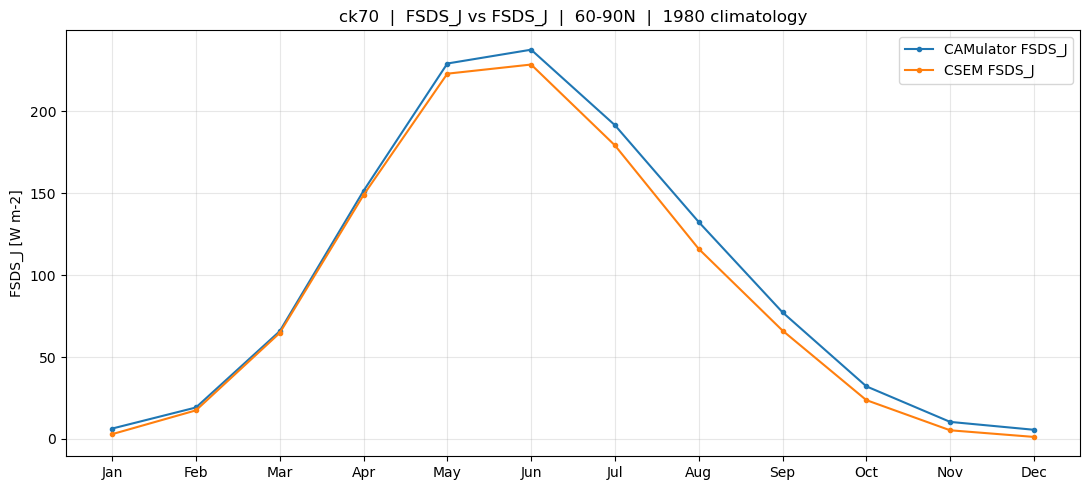

In [5]:
fig, ax = plot_series(cam, cesm, case=CASE)

## One month, year by year

`MONTHS = 1` with `CLIMATOLOGY = False` gives **one point per year** — every January
in `YEARS` on a real time axis, rather than the twelve-point seasonal cycle or the
full month-by-month series. This is the view that shows a drift in one month: whether
the two models are pulling apart January after January, or just noisy around each
other.

Set `YEARS` to a decade for it to be worth reading. `MONTHS = (12, 1, 2)` gives the
three winter months of each year instead, still one point per month.

The month goes into the title and the filename, so a Januarys figure never overwrites
the all-months one beside it in `fluxes/<VAR>/`.


wrote /glade/work/tvoeller/honors_thesis/code/output/ck70/fluxes/SHFLX/SHFLX_vs_SHFLX_Jan_60-90N_1980.png


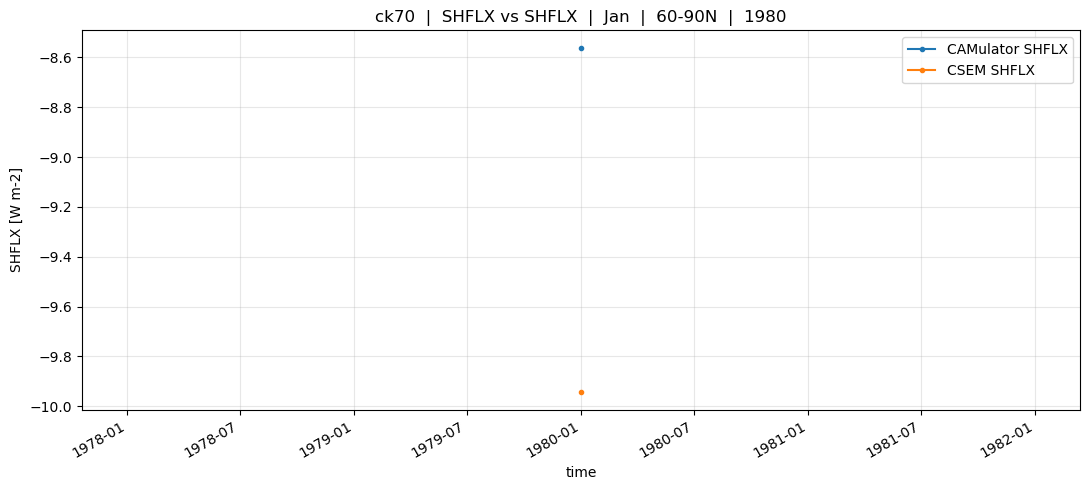

In [14]:
cam_jan, cesm_jan = flux_series(CASE, CAM_VAR, CESM_VAR, years=YEARS,
                                lat_range=LAT_RANGE, climatology=False, months=1)

fig, ax = plot_series(cam_jan, cesm_jan, case=CASE)


## Day by day through one month

`flux_series` collapses a month to a single point, so a January comparison is two dots
and the weather inside the month is gone. `flux_daily` gives **31 points a side**.

Both sides are **daily means**. CAMulator writes daily already, so CESM's four 6-hourly
steps are averaged per day to match. Drawing CESM at its native cadence against a
CAMulator line that is *already* a daily mean would make the emulator look the steadier
of the two, which is a fact about how its output was written and not about the model.
Averaged this way the two lines land on identical timestamps and read off one axis.

This is the one view the cache cannot serve — the cache is monthly means — so it reads
the raw output and takes a few seconds rather than being instant. `STEP_MONTH` takes
`YYYY-MM` for a whole month or `YYYY-MM-DD` for a single day.


wrote /glade/work/tvoeller/honors_thesis/code/output/ck70/fluxes/SHFLX/SHFLX_vs_SHFLX_daily_60-90N_1980-01.png


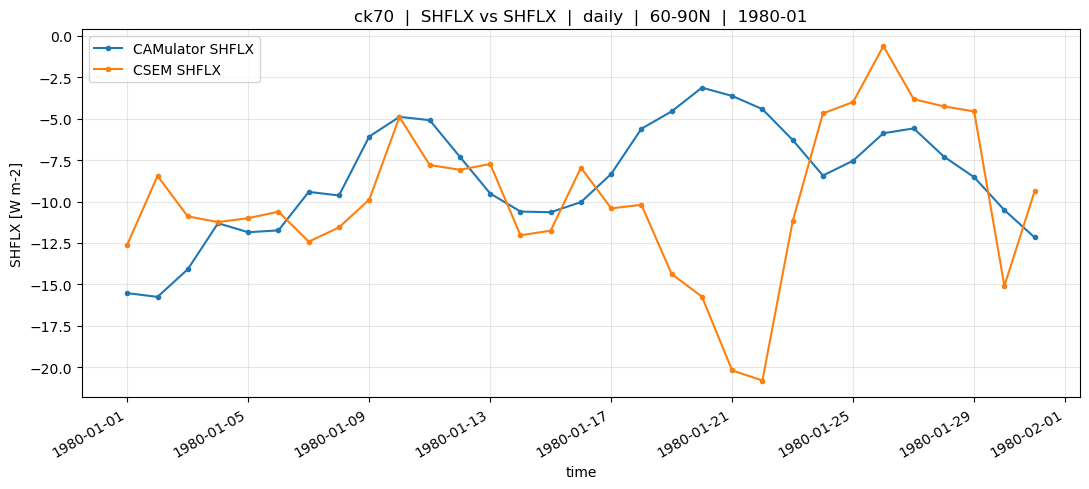

In [13]:
cam_daily, cesm_daily = flux_daily(CASE, CAM_VAR, CESM_VAR, when=STEP_MONTH,
                                   lat_range=LAT_RANGE)

fig, ax = plot_series(cam_daily, cesm_daily, case=CASE)


---

# Net radiation — down minus up

`FLDS_J` and `FSDS_J` are downwelling and carry **positive = energy into the surface**.
`FLUS` and `FSUS` are upwelling and carry **positive = upward**. So the net the surface
keeps is a plain `down - up`, and `flux_balance` returns all three: the two components
and their difference.

Two panels. The components share the top, coloured by component and dashed for CESM.
The net sits below on its own axis with a zero line, because it is tens of W/m² while
the terms behind it are hundreds, and one shared scale would flatten it onto the axis.

**Neither net is supposed to be zero.** Net longwave runs about -30 to -50 W/m² over
the Arctic: the surface radiates away more than the atmosphere returns. Net shortwave
is near zero through the polar night and peaks past 120 W/m² in midsummer. The thing
that does close is the whole budget, further down.

These cells pass `years=(1980, 1984)` and `climatology=True` outright so the first run
gives the intended figure. Swap in `YEARS` and `CLIMATOLOGY` once you have seen it.
`LAT_RANGE` is used as-is.


/glade/work/tvoeller/honors_thesis/code/ice_ens/fluxes.py:1024: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


wrote /glade/work/tvoeller/honors_thesis/code/output/ck70/fluxes/balance/FLDS_J-FLUS_60-90N_1980-1984_clim.png


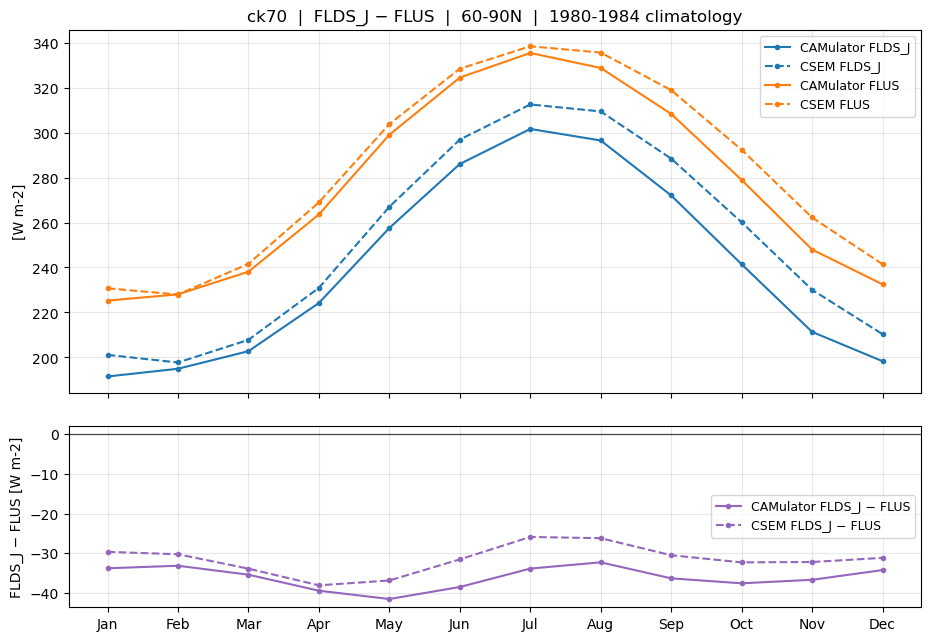

In [3]:
cam_lw, cesm_lw = flux_balance(CASE, "FLDS_J", "FLUS", years=(1980, 1984),
                               lat_range=LAT_RANGE, climatology=True)

fig, axes = plot_balance(cam_lw, cesm_lw, case=CASE)


## Shortwave

Same call, the other pair.


In [ ]:
cam_sw, cesm_sw = flux_balance(CASE, "FSDS_J", "FSUS", years=(1980, 1984),
                               lat_range=LAT_RANGE, climatology=True)

fig, axes = plot_balance(cam_sw, cesm_sw, case=CASE)


## The whole surface budget

Net shortwave, net longwave and the two turbulent fluxes, and the sum of all four —
the one combination that is meant to come out near zero:

```
net_sw    = FSDS_J - FSUS
net_lw    = FLDS_J - FLUS
turbulent = SHFLX + LHFLX        # both already positive-into-surface, so they add
budget    = net_sw + net_lw + turbulent
```

**Over 60-90N it will not close, and that is physics rather than a bug.** The Arctic
surface runs an annual deficit near -11 W/m² for CESM and -14 for the emulator, made up
by heat transported into the region, which none of these six fields carries. The
seasonal swing is far larger: about -55 in the polar night against +55 at midsummer,
which is the surface storing heat in summer and giving it back in winter.

Set `LAT_RANGE = None` to check the global closure instead. There the budget lands at
about +0.9 W/m² for CESM and +6.5 for the emulator, so the sign conventions are
consistent and the emulator carries a real 5.6 W/m² energy-budget bias.


In [ ]:
cam_bud, cesm_bud = flux_budget(CASE, years=(1980, 1984),
                                lat_range=LAT_RANGE, climatology=True)

fig, axes = plot_balance(cam_bud, cesm_bud, case=CASE)


---

# Spatially

Same cache, same window — the latitude band just isn't collapsed, so each side stays a
full `(latitude, longitude)` field. Two figures, laid out like the ice output:

| | goes to |
|---|---|
| one season, three panels (CAMulator, CESM, difference) | `fluxes/<VAR>/spatial/<SEASON>/<Region>/` |
| the whole seasonal cycle, one panel per month | `fluxes/<VAR>/spatial/12-Month/<Region>/` |

`REGION` picks both the projection and the directory: `"north"` → `Arctic`,
`"south"` → `Antarctic`, `"global"` → `Global`. The polar panels reuse the projection
and circular clip from the ice maps, so a flux map lines up with an ice map beside it.

Time series stay at `fluxes/<VAR>/` — only maps go under `spatial/`.

## One season — `SEASON`

`SEASON = (6, 7, 8)` gives JJA, `(12, 1, 2)` DJF, `7` Julys alone, `None` the annual
mean. The directory is named after whichever you pick, so JJA and DJF never overwrite
each other.

Three panels when both sides are the same variable: CAMulator, CESM, and their
difference on a scale centred on zero. Two different variables get one colorbar each
and **no difference panel**, since subtracting unlike fields means nothing.

wrote /glade/work/tvoeller/honors_thesis/code/output/ck70/fluxes/FSDS_J/spatial/Jan/Arctic/FSDS_J_vs_FSDS_J_Jan_1980.png


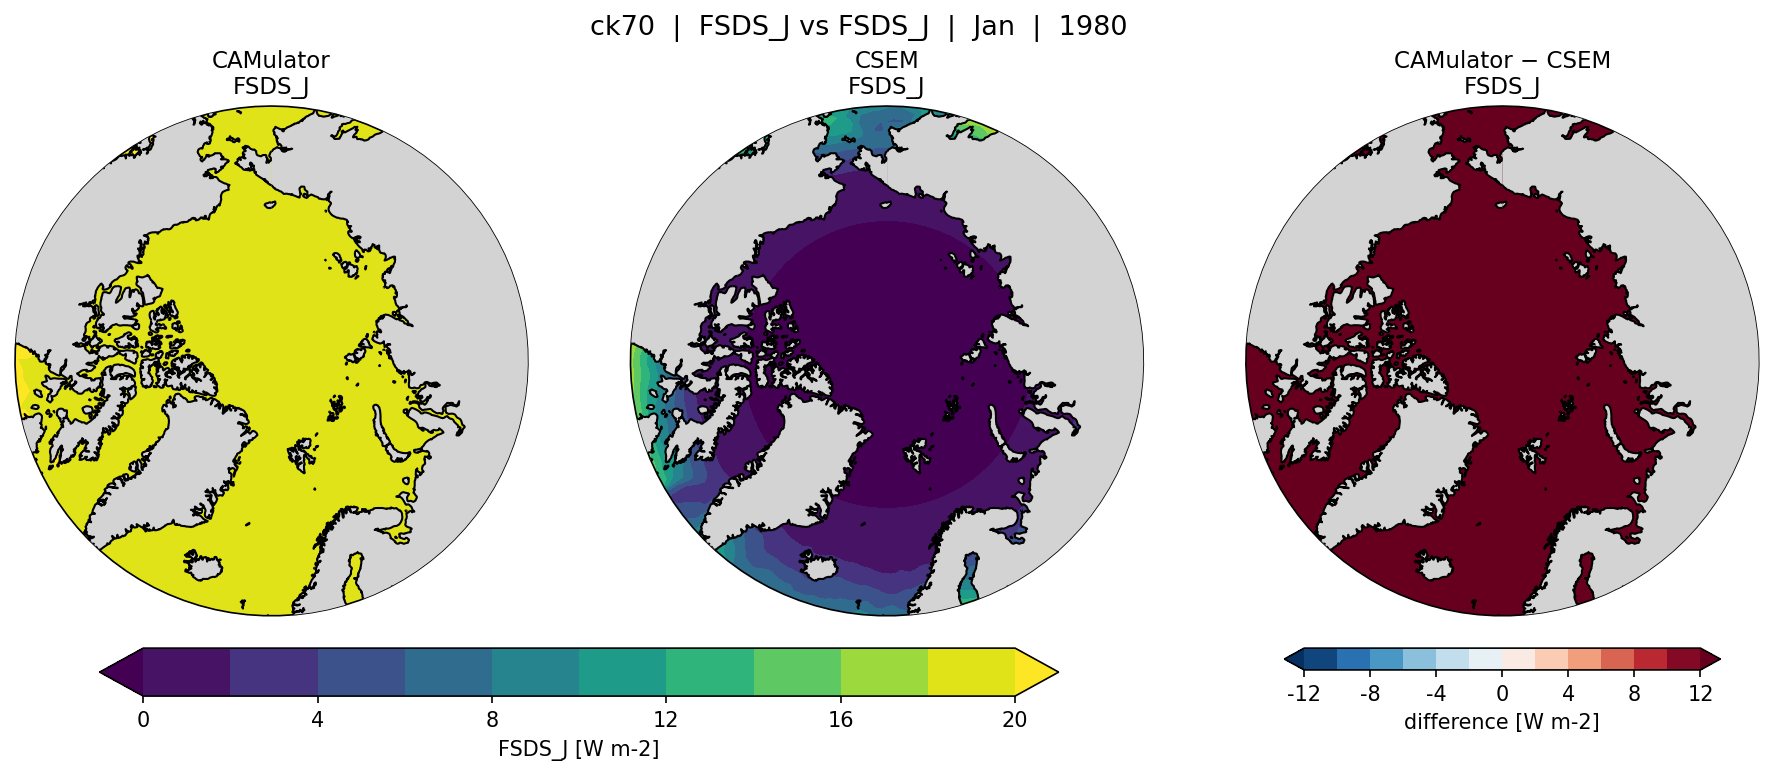

In [6]:
cam_map, cesm_map = flux_map(CASE, CAM_VAR, CESM_VAR, years=YEARS, months=SEASON)
fig, axes = plot_maps(cam_map, cesm_map, case=CASE, region=REGION)

## The 12-month grid

Twelve **separate** climatologies — each month averaged over every year in `YEARS` on
its own — so the seasonal cycle of the bias is visible instead of being averaged away.
The same distinction the ice `plot_month_grid` draws.

Every panel shares one colorbar, scaled across all twelve months together, so the
months are comparable by eye. Per-panel scales would hide exactly the signal this
figure exists to show.

`field=` picks what the panels show: `"difference"` (the default, CAMulator − CESM),
or `"camulator"` / `"cesm"` for one model's own field. `months=` takes any subset —
`[3, 6, 9, 12]` for the four seasons.

wrote /glade/work/tvoeller/honors_thesis/code/output/ck70/fluxes/FSDS_J/spatial/12-Month/Arctic/FSDS_J_vs_FSDS_J_camulator_bymonth_1980.png


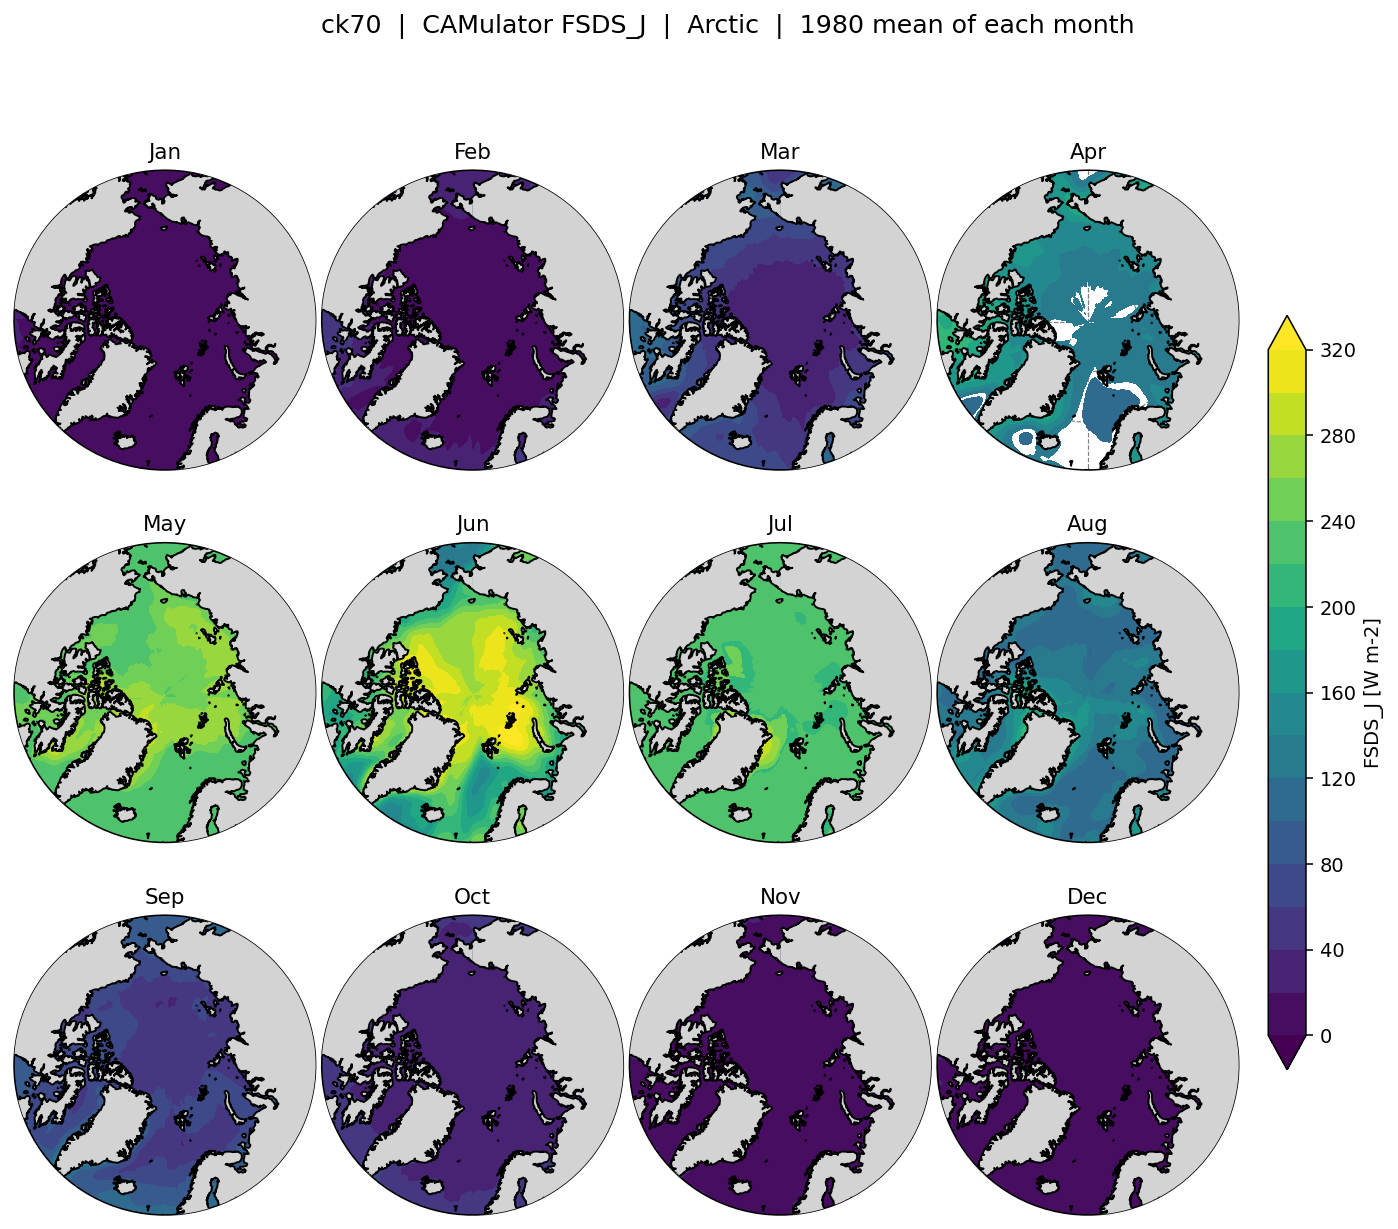

In [7]:
cam_months, cesm_months = flux_map_months(CASE, CAM_VAR, CESM_VAR, years=YEARS)
fig, axes = plot_map_grid(cam_months, cesm_months, case=CASE, region=REGION,
                          field="camulator")

---

## Initial conditions — one day

Everything above goes through monthly means, which is the wrong instrument for asking
how far apart the two models **start**: by the end of January a month of drift is
already folded in. `flux_day` reads one day and nothing else.

Both sides are that day's **mean**. A CAMulator daily file is already the mean of its
four 6-hourly steps, so CESM's four steps for the same date are averaged to match —
comparing the emulator's day against one CESM instant would be comparing a daily mean
with a snapshot.

This does not touch the cache, so `DAY` can be any date in the run, not just a year you
have already cached. The figure lands in `fluxes/<VAR>/spatial/<DAY>/<Region>/`.


In [ ]:
cam_day, cesm_day = flux_day(CASE, CAM_VAR, CESM_VAR, when=DAY)
fig, axes = plot_maps(cam_day, cesm_day, case=CASE, region=REGION)
